In [1]:
import os
import zipfile
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Set display preferences for Jupyter
%matplotlib inline
pd.set_option('display.max_columns', None)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# ML Classification Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    roc_curve
)

# Ensure required directory structure exists
os.makedirs("model", exist_ok=True)
print("Environment and packages loaded successfully.")

Environment and packages loaded successfully.


# Step 1: Dataset choice

In [2]:
csv_filepath = "bank.csv"

# Automatically fetch and extract UCI Bank Marketing dataset if not present locally
if not os.path.exists(csv_filepath):
    print("Fetching dataset from UCI Machine Learning Repository...")
    dataset_url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
    zip_path = "bank_marketing.zip"
    
    try:
        urllib.request.urlretrieve(dataset_url, zip_path)
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(".")
            
        if os.path.exists("bank.zip"):
            with zipfile.ZipFile("bank.zip", 'r') as inner_zip:
                inner_zip.extractall(".")
        print("Dataset downloaded and extracted successfully.")
    except Exception as err:
        print(f"Direct download failed: {err}")
        print("Please ensure bank.csv is placed directly in the notebook working directory.")
else:
    print("bank.csv already exists locally.")

# UCI bank.csv uses semicolons (;) as delimiters
df = pd.read_csv(csv_filepath, sep=";")
print(f"Total instances: {df.shape[0]} | Total features: {df.shape[1]}")
df.head()

Fetching dataset from UCI Machine Learning Repository...
Dataset downloaded and extracted successfully.
Total instances: 4521 | Total features: 17


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


In [3]:
# Check and drop duplicates
initial_rows = len(df)
df = df.drop_duplicates()
print(f"Duplicates removed: {initial_rows - len(df)}")

# In UCI Bank dataset, missing values are denoted by string 'unknown'
# Replace 'unknown' with np.nan so that SimpleImputer can process them
df.replace("unknown", np.nan, inplace=True)

# Separate features (X) and target (y)
target_col = 'y' if 'y' in df.columns else 'deposit'
X = df.drop(columns=[target_col])
y = df[target_col].map({'no': 0, 'yes': 1}).values

# Class Distribution Analysis
class_0_count = np.sum(y == 0)
class_1_count = np.sum(y == 1)
print(f"\nClass Distribution:")
print(f"  Class 0 ('no'):  {class_0_count} ({class_0_count / len(y):.2%})")
print(f"  Class 1 ('yes'): {class_1_count} ({class_1_count / len(y):.2%})")

# Feature identification
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
print(f"\nNumerical columns ({len(num_cols)}): {num_cols}")
print(f"Categorical columns ({len(cat_cols)}): {cat_cols}")

Duplicates removed: 0

Class Distribution:
  Class 0 ('no'):  4000 (88.48%)
  Class 1 ('yes'): 521 (11.52%)

Numerical columns (7): ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Categorical columns (9): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [4]:
# 80:20 Stratified Train-Test Split with a fixed random seed
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Train set: {X_train.shape[0]} instances")
print(f"Test set:  {X_test.shape[0]} instances")

# Save test dataset as test_data.csv (Mandatory requirement)
test_data_export = X_test.copy()
test_data_export['target'] = y_test
test_data_export.to_csv("test_data.csv", index=False)
print("Exported test_data.csv to current directory.")

Train set: 3616 instances
Test set:  905 instances
Exported test_data.csv to current directory.


In [5]:
# Pipeline for numerical features (median imputation + standardization)
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Pipeline for categorical features (mode imputation + one-hot encoding)
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

# Fit on training data ONLY to prevent data leakage
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

# Save fitted preprocessor
joblib.dump(preprocessor, "model/preprocessor.joblib")
print(f"Preprocessed feature count: {X_train_prep.shape[1]}")
print("Fitted preprocessor saved to model/preprocessor.joblib")

Preprocessed feature count: 47
Fitted preprocessor saved to model/preprocessor.joblib


In [6]:
os.environ["LOKY_MAX_CPU_COUNT"] = "4"
# Define all 5 required classification models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, random_state=42),
    "kNN": KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes": GaussianNB(),
    "Random Forest (Ensemble)": RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
}

results = []

for name, clf in models.items():
    # 1. Train model
    clf.fit(X_train_prep, y_train)
    
    # 2. Serialize model to disk
    file_slug = name.lower().replace(" ", "_").replace("(", "").replace(")", "")
    joblib.dump(clf, f"model/{file_slug}.joblib")
    
    # 3. Predict labels and probabilities
    y_pred = clf.predict(X_test_prep)
    if hasattr(clf, "predict_proba"):
        y_prob = clf.predict_proba(X_test_prep)[:, 1]
    else:
        y_prob = clf.decision_function(X_test_prep)

    # 4. Compute all 6 required evaluation metrics
    acc = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    mcc = matthews_corrcoef(y_test, y_pred)

    results.append({
        "ML Model Name": name,
        "Accuracy": round(acc, 4),
        "AUC": round(auc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1": round(f1, 4),
        "MCC": round(mcc, 4)
    })

# Format comparison table
results_df = pd.DataFrame(results)
display(results_df)

,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8950,0.8751,0.5882,0.2885,0.3871,0.3627
1,Decision Tree,0.8829,0.8111,0.4821,0.2596,0.3375,0.2957
2,kNN,0.8906,0.7781,0.5806,0.1731,0.2667,0.2750
3,Naive Bayes,0.8343,0.7804,0.3357,0.4519,0.3852,0.2962
4,Random Forest (Ensemble),0.8939,0.8888,0.6667,0.1538,0.2500,0.2855


C:\Users\sc176\AppData\Local\Temp\ipykernel_16524\265926015.py:9: UserWarning: The palette list has more values (10) than needed (5), which may not be intended.
  barplot = sns.barplot(


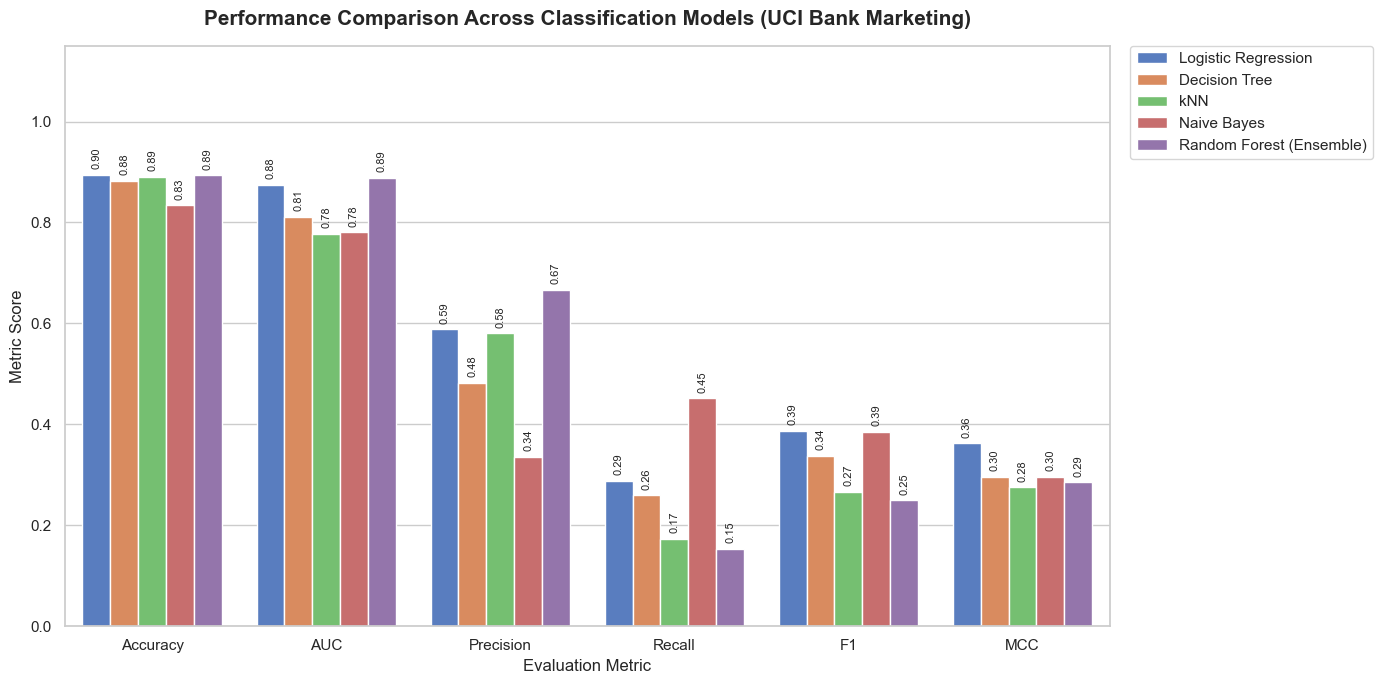

Saved visualization to model_evaluation_metrics.png


In [7]:
metrics = ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]
melted_df = pd.melt(results_df, id_vars=["ML Model Name"], value_vars=metrics, 
                    var_name="Metric", value_name="Score")

plt.figure(figsize=(14, 7))
sns.set_theme(style="whitegrid")
palette = sns.color_palette("muted")

barplot = sns.barplot(
    data=melted_df, 
    x="Metric", 
    y="Score", 
    hue="ML Model Name", 
    palette=palette
)

plt.title("Performance Comparison Across Classification Models (UCI Bank Marketing)", fontsize=15, weight="bold", pad=15)
plt.ylim(0, 1.15)
plt.ylabel("Metric Score", fontsize=12)
plt.xlabel("Evaluation Metric", fontsize=12)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)

# Add exact score annotations above bars
for p in barplot.patches:
    h = p.get_height()
    if h > 0.02:
        barplot.annotate(
            f"{h:.2f}",
            (p.get_x() + p.get_width() / 2., h),
            ha='center', va='bottom',
            fontsize=8, rotation=90, xytext=(0, 4),
            textcoords='offset points'
        )

plt.tight_layout()
plt.savefig("model_evaluation_metrics.png", dpi=300)
plt.show()
print("Saved visualization to model_evaluation_metrics.png")